# Mushroom Dataset - Exploratory Data Analysis

## Contributors
- Pamela: EDA, visualisations and interpretation
- Liam: Review and made some improvements

Before we start cleaning the data or training models, we first want to get a good idea of what’s actually in the dataset.

We’ll check:
- what columns and data types we have
- how many edible and poisonous mushrooms there are
- where values are missing
- how the numerical features are spread out
- how the categorical features are divided
- which features seem related to edible/poisonous mushrooms
- whether the `jumbled_noise` columns are actually useful or just random noise

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("mushroom_project_dataset.csv")

df.head()

,cap-diameter,stem-height,stem-width,spore-print-color,gill-color,habitat,season,ring-type,cap-shape,stem-surface,jumbled_noise_0,jumbled_noise_1,class
0,NaN,6.42,13.51,NaN,NaN,d,u,g,x,NaN,x,c,p
1,6.99,7.68,18.76,NaN,w,d,a,f,f,s,f,f,e
2,5.78,7.67,8.21,NaN,r,d,u,f,c,NaN,c,x,p
3,6.34,8.34,11.06,NaN,NaN,d,a,z,x,NaN,x,b,p
4,NaN,5.67,12.78,NaN,n,d,NaN,f,x,NaN,s,s,e


In [2]:
df.shape

(5000, 13)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   cap-diameter       2968 non-null   float64
 1   stem-height        3987 non-null   float64
 2   stem-width         4605 non-null   float64
 3   spore-print-color  260 non-null    object 
 4   gill-color         4011 non-null   object 
 5   habitat            3996 non-null   object 
 6   season             4027 non-null   object 
 7   ring-type          4423 non-null   object 
 8   cap-shape          4594 non-null   object 
 9   stem-surface       1641 non-null   object 
 10  jumbled_noise_0    4594 non-null   object 
 11  jumbled_noise_1    4594 non-null   object 
 12  class              5000 non-null   object 
dtypes: float64(3), object(10)
memory usage: 507.9+ KB


In [4]:
df.describe(include="all")

,cap-diameter,stem-height,stem-width,spore-print-color,gill-color,habitat,season,ring-type,cap-shape,stem-surface,jumbled_noise_0,jumbled_noise_1,class
count,2968.000000,3987.000000,4605.000000,260,4011,3996,4027,4423,4594,1641,4594,4594,5000
unique,NaN,NaN,NaN,7,12,8,4,8,7,8,7,7,2
top,NaN,NaN,NaN,k,w,d,a,f,x,s,x,x,e
freq,NaN,NaN,NaN,74,1339,2957,2010,3653,2060,510,2060,2060,3107
mean,7.161439,6.693832,12.885110,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,5.985060,3.454998,10.610543,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.500000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,3.830000,4.800000,5.940000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,6.140000,6.010000,11.280000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,8.785000,7.740000,17.050000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Initial observations

The dataset contains 5,000 observations and 13 columns.
The target variable is `class`.

The dataset contains both numerical and categorical features and several columns contain substantial amounts of missing data.
Meaning that missing-value handling will be an important preprocessing decision.

In [5]:
df["class"].value_counts()

class
e    3107
p    1893
Name: count, dtype: int64

In [6]:
df["class"].value_counts(normalize=True) * 100

class
e    62.14
p    37.86
Name: proportion, dtype: float64

In [7]:
df["class"].value_counts().plot(kind="bar")
plt.title("Distribution of Mushroom Classes")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

<Figure size 640x480 with 1 Axes>

In [8]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
})

missing.sort_values("missing_percentage", ascending=False)

,missing_count,missing_percentage
spore-print-color,4740,94.80
stem-surface,3359,67.18
cap-diameter,2032,40.64
stem-height,1013,20.26
habitat,1004,20.08
gill-color,989,19.78
season,973,19.46
ring-type,577,11.54
cap-shape,406,8.12
jumbled_noise_0,406,8.12


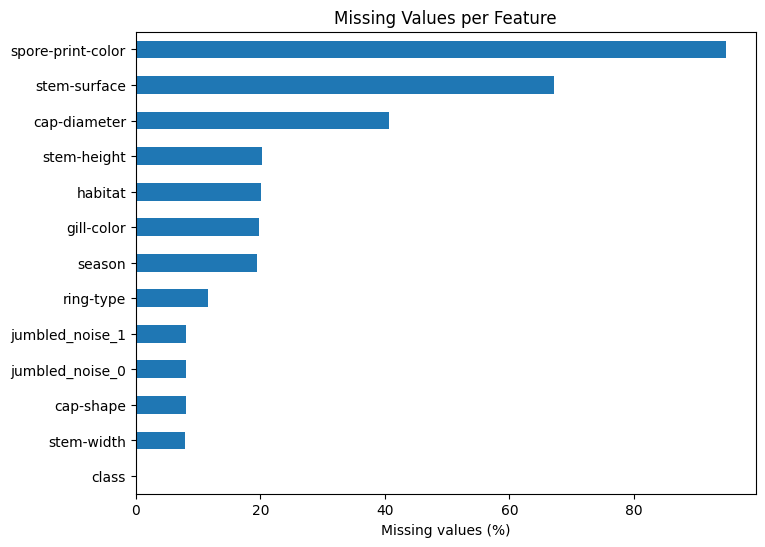

In [9]:
missing["missing_percentage"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Missing values (%)")
plt.title("Missing Values per Feature")
plt.show()

- spore-print-color has around 95% missing values, so we need to check if it is still worth keeping.
- stem-surface might be usable, requires more investigation.
- cap-diameter might be too important to throw away without testing.

In [10]:
numeric_columns = [
    "cap-diameter",
    "stem-height",
    "stem-width"
]

df[numeric_columns].describe()

,cap-diameter,stem-height,stem-width
count,2968.000000,3987.000000,4605.000000
mean,7.161439,6.693832,12.885110
std,5.985060,3.454998,10.610543
min,0.500000,0.000000,0.000000
25%,3.830000,4.800000,5.940000
50%,6.140000,6.010000,11.280000
75%,8.785000,7.740000,17.050000
max,57.400000,32.430000,102.480000


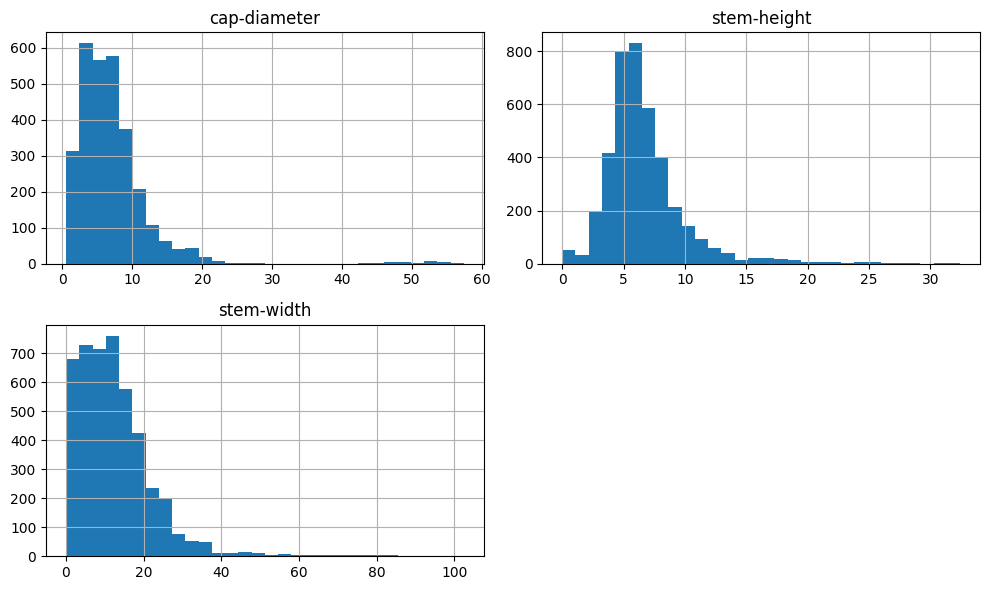

In [11]:
df[numeric_columns].hist(figsize=(10, 6), bins=30)
plt.tight_layout()
plt.show()

We want to know if there are strange values, outliers, if the distributions are heavily skewed and if the poisonous and edible mushrooms look different.

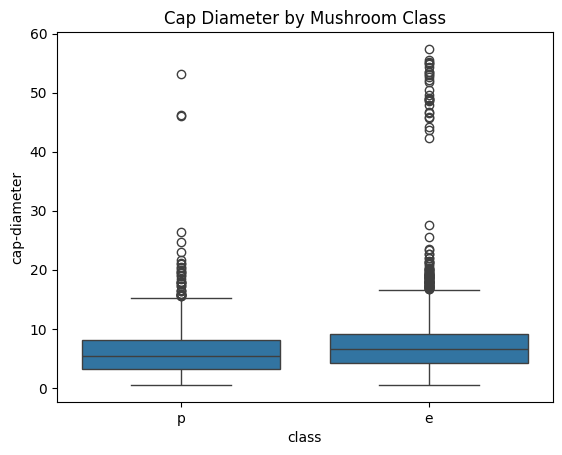

In [12]:
sns.boxplot(
    data=df,
    x="class",
    y="cap-diameter"
)

plt.title("Cap Diameter by Mushroom Class")
plt.show()

### Cap diameter observations

Both edible and poisonous mushrooms show many outliers in cap diameter.
Some measurements are a bit different for edible and poisonous mushrooms, but the two groups still overlap quite a lot.

There are some extreme values above 40–50, mainly in the edible class.
We will not remove these outliers now because they can be valid mushrooms rather than errors.

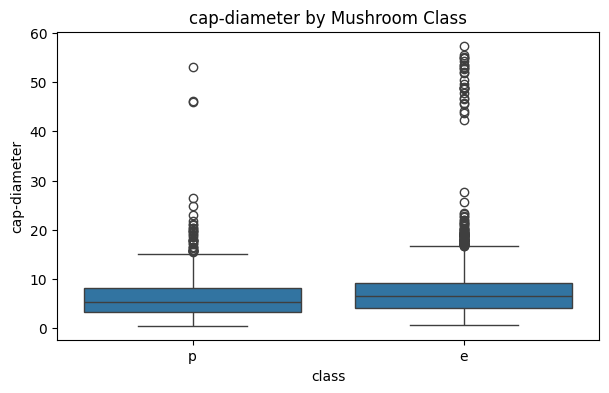

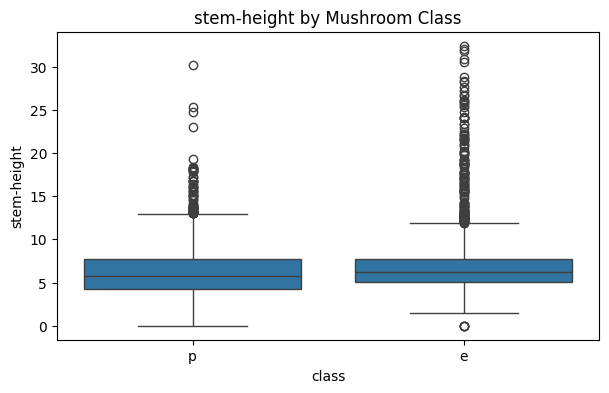

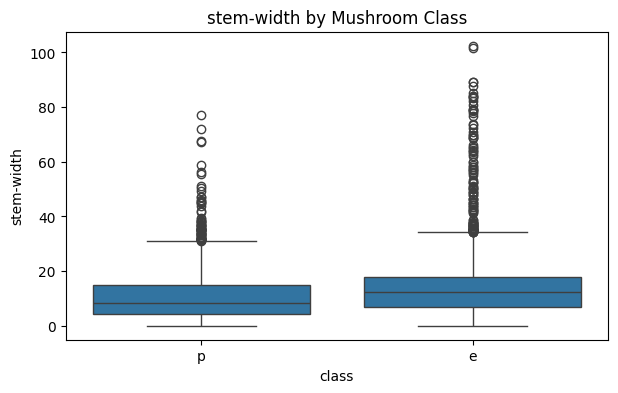

In [13]:
numeric_columns = ["cap-diameter", "stem-height", "stem-width"]

for column in numeric_columns:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="class",
        y=column
    )

    plt.title(f"{column} by Mushroom Class")
    plt.show()

### Numerical feature observations

Some measurements are a bit different for edible and poisonous mushrooms, but the two groups still overlap quite a lot.

The clearest difference seems to be in stem width, where edible mushrooms usually have a higher middle value.

The boxplots also show quite a few outliers. Looking at mushrooms with a cap diameter above 40, most are edible, but there are poisonous ones too.

Gotta investigate further during data cleaning.

In [14]:
df["cap-diameter"].sort_values(ascending=False).head(20)

3262    57.40
3519    55.49
3007    55.16
2181    54.98
280     54.81
2389    54.35
2775    53.57
4776    53.41
2986    53.09
542     53.09
81      52.94
4445    52.59
2192    52.12
619     51.88
4077    50.49
4406    49.55
3434    49.03
3649    48.91
2460    48.86
361     48.76
Name: cap-diameter, dtype: float64

In [15]:
df[df["cap-diameter"] > 40][
    ["cap-diameter", "stem-height", "stem-width", "class"]
]

,cap-diameter,stem-height,stem-width,class
10,46.61,6.72,34.72,e
80,42.27,4.24,NaN,e
81,52.94,NaN,32.65,e
280,54.81,NaN,25.02,e
361,48.76,6.42,42.49,e
514,43.70,5.46,26.63,e
542,53.09,NaN,20.59,p
619,51.88,7.00,37.62,e
999,46.68,5.87,36.92,e
1263,46.26,7.59,28.31,p


In [16]:
categorical_columns = [
    "spore-print-color",
    "gill-color",
    "habitat",
    "season",
    "ring-type",
    "cap-shape",
    "stem-surface"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- spore-print-color ---
spore-print-color
NaN    4740
k        74
w        60
p        57
n        40
g        23
u         3
r         3
Name: count, dtype: int64

--- gill-color ---
gill-color
w      1339
NaN     989
y       617
n       574
p       351
g       282
f       220
o       196
k       136
r        91
b        79
u        64
e        62
Name: count, dtype: int64

--- habitat ---
habitat
d      2957
NaN    1004
g       440
l       229
m       194
h       112
w        31
p        22
u        11
Name: count, dtype: int64

--- season ---
season
a      2010
u      1406
NaN     973
w       396
s       215
Name: count, dtype: int64

--- ring-type ---
ring-type
f      3653
NaN     577
e       192
l       132
g       113
r       108
p        98
z        87
m        40
Name: count, dtype: int64

--- cap-shape ---
cap-shape
x      2060
f      1078
s       533
NaN     406
b       354
o       218
p       207
c       144
Name: count, dtype: int64

--- stem-surface ---
stem-surface
NaN

In [17]:
for column in categorical_columns:
    display(
        pd.crosstab(
            df[column],
            df["class"],
            normalize="index"
        ).round(3)
    )

class,e,p
spore-print-color,,
g,0.957,0.043
k,0.405,0.595
n,0.100,0.900
p,0.491,0.509
r,0.000,1.000
u,0.333,0.667
w,0.800,0.200


class,e,p
gill-color,,
b,0.797,0.203
e,0.419,0.581
f,0.614,0.386
g,0.684,0.316
k,0.669,0.331
n,0.538,0.462
o,0.597,0.403
p,0.624,0.376
r,0.505,0.495


class,e,p
habitat,,
d,0.632,0.368
g,0.548,0.452
h,0.518,0.482
l,0.734,0.266
m,0.675,0.325
p,0.182,0.818
u,0.818,0.182
w,0.903,0.097


class,e,p
season,,
a,0.598,0.402
s,0.688,0.312
u,0.620,0.380
w,0.727,0.273


class,e,p
ring-type,,
e,0.635,0.365
f,0.623,0.377
g,0.681,0.319
l,0.667,0.333
m,0.900,0.100
p,0.673,0.327
r,0.639,0.361
z,0.069,0.931


class,e,p
cap-shape,,
b,0.404,0.596
c,0.576,0.424
f,0.672,0.328
o,0.427,0.573
p,0.729,0.271
s,0.602,0.398
x,0.646,0.354


class,e,p
stem-surface,,
f,0.071,0.929
g,0.077,0.923
h,0.074,0.926
i,0.569,0.431
k,0.564,0.436
s,0.747,0.253
t,0.627,0.373
y,0.512,0.488


### Categorical feature observations

Some of the categorical features already seem pretty useful for telling edible and poisonous mushrooms apart.

A good example is `spore-print-color`. Some colors are mostly linked to edible mushrooms, while others are mostly linked to poisonous ones (we still need to remember that r and u only have a few rows).

The only problem is that this column has a lot of missing values, so even if it looks useful, we still need to see if it is actually worth keeping in the final model.

We’ll check the other categorical features in the same way and see which ones actually seem helpful.

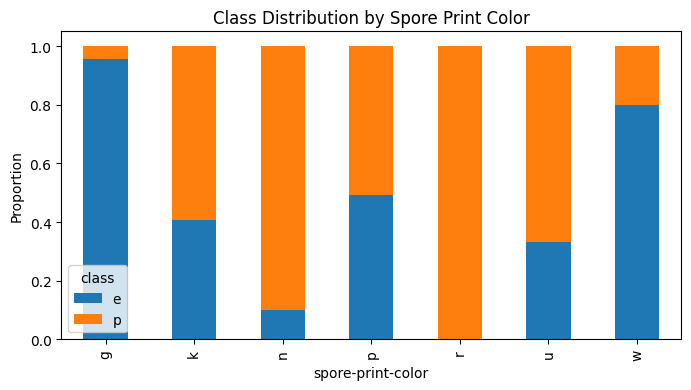

In [18]:
pd.crosstab(
    df["spore-print-color"],
    df["class"],
    normalize="index"
).plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4)
)

plt.ylabel("Proportion")
plt.title("Class Distribution by Spore Print Color")
plt.show()

### Other categorical features

Now we’ll look at some of the other categorical features and see if certain categories are more strongly linked to edible or poisonous mushrooms.

We’re mainly looking for features where the proportions between the two classes are clearly different, bcs those could be useful for the model.

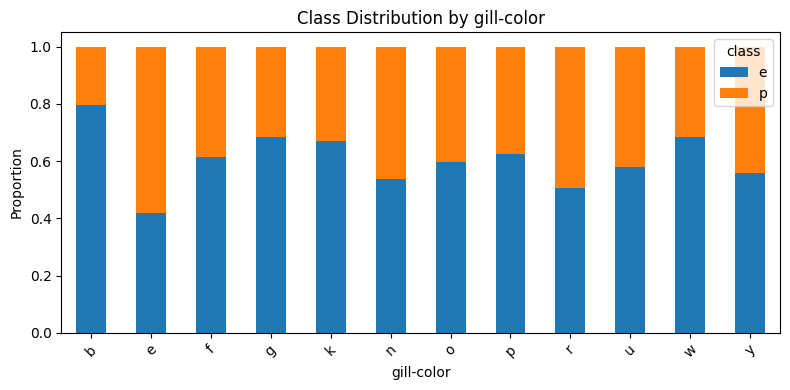

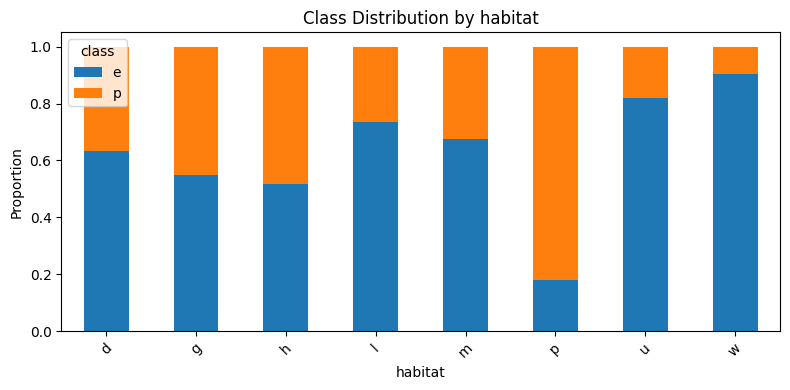

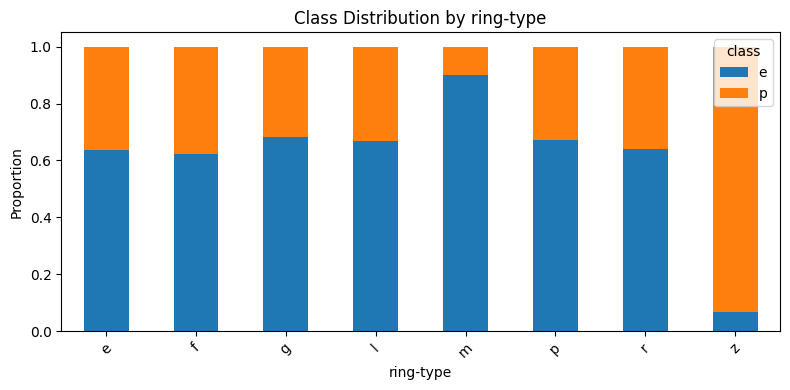

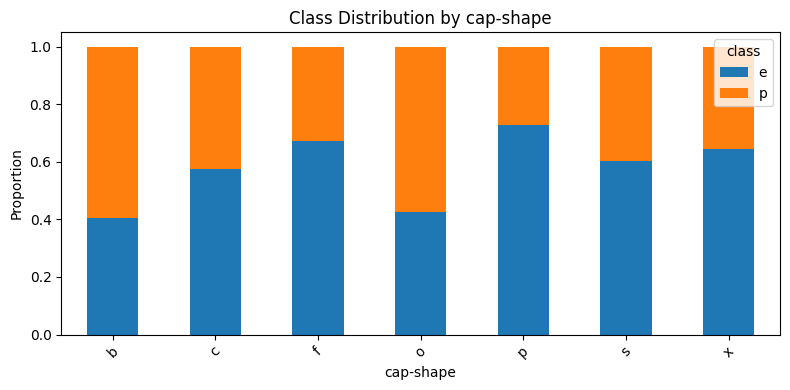

In [19]:
categorical_to_plot = [
    "gill-color",
    "habitat",
    "ring-type",
    "cap-shape"
]

for column in categorical_to_plot:
    pd.crosstab(
        df[column],
        df["class"],
        normalize="index"
    ).plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )

    plt.ylabel("Proportion")
    plt.title(f"Class Distribution by {column}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### What we see in the other categorical features

Some of these features look way more useful than others.

`habitat` seems pretty interesting. Mushrooms in habitat `p` are mostly poisonous, while `u` and `w` are mostly edible.

`ring-type` also stands out. Ring type `z` is almost always poisonous, while `m` is mostly edible.

`cap-shape` shows some differences too, but the classes are more mixed.
`gill-color` looks less useful on its own because most colors have both edible and poisonous mushrooms.

So for now, `habitat` and `ring-type` look like some of the more useful categorical features.

### Statistical check: ring type and class

`ring-type` looked useful in the graph above.

To check if ring type and mushroom class are actually related, we use a chi-square test.

- **H0:** Ring type and mushroom class are not related.
- **H1:** Ring type and mushroom class are related.

In [20]:
from scipy.stats import chi2_contingency

ring_table = pd.crosstab(df["ring-type"], df["class"])

chi2, p_value, dof, expected = chi2_contingency(ring_table)

print("Chi-square:", round(chi2, 2))
print("p-value:", p_value)

if p_value < 0.05:
    print("Ring type and mushroom class are related.")
else:
    print("We did not find enough evidence that ring type and mushroom class are related.")

Chi-square: 130.02
p-value: 6.21584303401692e-25
Ring type and mushroom class are related.


### Result

The p-value is below 0.05.

This means the pattern we saw in the graph is probably not random. `ring-type` seems to be related to whether a mushroom is edible or poisonous.

In [21]:
for column in ["jumbled_noise_0", "jumbled_noise_1"]:
    print(f"\n--- {column} ---")

    display(
        pd.crosstab(
            df[column],
            df["class"],
            normalize="index"
        ).round(3)
    )


--- jumbled_noise_0 ---


class,e,p
jumbled_noise_0,,
b,0.624,0.376
c,0.569,0.431
f,0.620,0.380
o,0.656,0.344
p,0.638,0.362
s,0.614,0.386
x,0.629,0.371



--- jumbled_noise_1 ---


class,e,p
jumbled_noise_1,,
b,0.613,0.387
c,0.521,0.479
f,0.647,0.353
o,0.550,0.450
p,0.623,0.377
s,0.589,0.411
x,0.634,0.366


### Noise columns

`jumbled_noise_0` is close to the overall class balance. `jumbled_noise_1` has a small apparent association, so we should not call both columns pure noise from the plots alone. We will quantify this below and treat the result as exploratory evidence rather than proof of usefulness.

In [22]:
# Check whether missingness itself is associated with the target
missingness_by_class = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "poisonous_if_missing": [
        df.loc[df[column].isna(), "class"].eq("p").mean()
        if df[column].isna().any() else None
        for column in df.columns
    ],
    "poisonous_if_observed": [
        df.loc[df[column].notna(), "class"].eq("p").mean()
        if df[column].notna().any() else None
        for column in df.columns
    ],
}, index=df.columns)
missingness_by_class.sort_values("missing_percentage", ascending=False)

,missing_count,missing_percentage,poisonous_if_missing,poisonous_if_observed
spore-print-color,4740,94.80,0.372574,0.488462
stem-surface,3359,67.18,0.354570,0.427788
cap-diameter,2032,40.64,0.383366,0.375337
stem-height,1013,20.26,0.378085,0.378731
habitat,1004,20.08,0.402390,0.372623
gill-color,989,19.78,0.381193,0.377961
season,973,19.46,0.386434,0.376707
ring-type,577,11.54,0.362218,0.380737
cap-shape,406,8.12,0.357143,0.380496
jumbled_noise_0,406,8.12,0.413793,0.375490


In [23]:
# Inspect zeros and Tukey outliers before deciding whether to remove them
numeric_columns = ["cap-diameter", "stem-height", "stem-width"]
numeric_quality = []

for column in numeric_columns:
    values = df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    numeric_quality.append({
        "feature": column,
        "zero_count": int((values == 0).sum()),
        "negative_count": int((values < 0).sum()),
        "outlier_count": int(((values < lower) | (values > upper)).sum()),
        "min": values.min(),
        "max": values.max(),
    })

pd.DataFrame(numeric_quality)

,feature,zero_count,negative_count,outlier_count,min,max
0,cap-diameter,0,0,134,0.5,57.40
1,stem-height,49,0,271,0.0,32.43
2,stem-width,57,0,164,0.0,102.48


In [24]:
# Compare categorical association strength, not only p-values
from scipy.stats import chi2_contingency

association_results = []
categorical_columns = df.select_dtypes(include="object").columns.drop("class")
for column in categorical_columns:
    table = pd.crosstab(df[column].fillna("<missing>"), df["class"])
    chi2, p_value, _, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    rows, columns = table.shape
    cramers_v = (phi2 / min(columns - 1, rows - 1)) ** 0.5
    association_results.append({
        "feature": column,
        "p_value": p_value,
        "cramers_v": cramers_v,
    })
associations = pd.DataFrame(association_results).sort_values("p_value")
ranks = pd.Series(range(1, len(associations) + 1), index=associations.index)
adjusted = associations["p_value"] * len(associations) / ranks
associations["p_value_bh"] = adjusted.iloc[::-1].cummin().iloc[::-1].clip(upper=1)
associations

,feature,p_value,cramers_v,p_value_bh
6,stem-surface,1.918515e-53,0.231790,1.726663e-52
5,cap-shape,2.953011e-26,0.165137,1.328855e-25
4,ring-type,1.712637e-24,0.161896,5.137911e-24
0,spore-print-color,8.353542e-17,0.134782,1.879547e-16
1,gill-color,1.826046e-12,0.127948,3.286883e-12
2,habitat,7.584240e-11,0.113143,1.137636e-10
3,season,1.305072e-05,0.074703,1.677949e-05
8,jumbled_noise_1,1.327258e-02,0.059540,1.493165e-02
7,jumbled_noise_0,5.609142e-01,0.034118,5.609142e-01


## EDA conclusion

We now have a pretty good idea of what is going on in the dataset.

There are quite a lot of missing values, especially in `spore-print-color` and `stem-surface`, so we need to decide how to handle those during cleaning.

Some numerical features seem useful, but edible and poisonous mushrooms still overlap quite a lot.

Some categorical features, especially `habitat`, `ring-type` and `spore-print-color`, show clearer differences between the two classes.

The chi-square test also showed that `ring-type` is related to mushroom class, so this feature looks useful for prediction.

`stem-surface` also shows some strong differences for the values that are available, but around 67% of this column is missing.

Missingness is not completely random: for example, `spore-print-color` is much more poisonous when observed than when missing. The missingness indicators should therefore be preserved during preprocessing.

The numeric features contain zero values and substantial Tukey outliers. We will inspect these rather than automatically deleting them, because they may be valid measurements.

`jumbled_noise_0` looks consistent with noise, while `jumbled_noise_1` has a small association that should be tested with cross-validation before deciding whether to remove it.

Next:
start preparing the data for modelling.